# Review 3: Multi-Variant ResNet-50 Training & Benchmarking
**Capstone Project:** Automated Pediatric Bone Age Estimation (`PW_27_COP_01`)
**Role:** Deep Learning Architect (Nishanth T Chigilar)

This notebook benchmarks ResNet-50 continuous age regression across 4 image preprocessing pipelines:
1. **RAW:** Unprocessed PA radiographs
2. **CLAHE:** Baseline contrast-limited adaptive histogram equalization
3. **HYBRID:** CLAHE + Top-Hat + Gamma Correction + Z-Score Normalization
4. **UNET_MASKED:** U-Net background contour masked & cropped hand outlines

In [1]:
# ==============================================================================
# Cell 1: Environment Setup, Pure Python Unzip & Automatic CSV Split
# ==============================================================================
import os
import zipfile
import pandas as pd
from google.colab import drive
from sklearn.model_selection import train_test_split

print("1. Mounting Google Drive...")
drive.mount('/content/drive')

DATA_ROOT = "/content/data"
RAW_DIR = os.path.join(DATA_ROOT, "raw")
CLAHE_DIR = os.path.join(DATA_ROOT, "clahe")
HYBRID_DIR = os.path.join(DATA_ROOT, "hybrid")
UNET_DIR = os.path.join(DATA_ROOT, "unet_masked")
CHECKPOINT_DIR = "/content/checkpoints"

for d in [RAW_DIR, CLAHE_DIR, HYBRID_DIR, UNET_DIR, CHECKPOINT_DIR]:
    os.makedirs(d, exist_ok=True)

ZIP_PATH = "/content/drive/MyDrive/RSNA_Bone_Age/01_RAW_RSNA_DATASET/archive.zip"

if os.path.exists(ZIP_PATH) and len(os.listdir(RAW_DIR)) == 0:
    print(f"2. Unzipping raw archive directly to local NVMe RAM disk...")
    with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
        zip_ref.extractall(RAW_DIR)
    print("   Unzip complete!")
else:
    print(f"✅ Local NVMe directory initialized at {RAW_DIR}")

# Resolve training image folder explicitly
IMG_FOLDER = None
for root, dirs, files in os.walk(RAW_DIR):
    png_files = [f for f in files if f.endswith('.png') or f.endswith('.jpg')]
    if "training" in root.lower() and len(png_files) > 1000:
        IMG_FOLDER = root
        break

if not IMG_FOLDER:
    max_files = 0
    for root, dirs, files in os.walk(RAW_DIR):
        png_files = [f for f in files if f.endswith('.png') or f.endswith('.jpg')]
        if len(png_files) > max_files:
            max_files = len(png_files)
            IMG_FOLDER = root

print(f"✅ Training images path resolved: {IMG_FOLDER} ({len(os.listdir(IMG_FOLDER))} images found)")

# Resolve CSV metadata
csv_candidates = [
    os.path.join(RAW_DIR, "boneage-training-dataset.csv"),
    os.path.join(IMG_FOLDER, "boneage-training-dataset.csv"),
    "/content/drive/MyDrive/RSNA_Bone_Age/boneage-training-dataset.csv",
    "/content/drive/MyDrive/RSNA_Bone_Age/train.csv"
]
source_csv = next((p for p in csv_candidates if os.path.exists(p)), None)

if source_csv:
    df = pd.read_csv(source_csv)
    df.columns = [c.lower().strip() for c in df.columns]
    train_df, valid_df = train_test_split(df, test_size=0.15, random_state=42)
    train_df.to_csv(os.path.join(DATA_ROOT, "train.csv"), index=False)
    valid_df.to_csv(os.path.join(DATA_ROOT, "valid.csv"), index=False)
    print(f"✅ Metadata splits generated: train.csv ({len(train_df)} rows) | valid.csv ({len(valid_df)} rows)")

1. Mounting Google Drive...
Mounted at /content/drive
2. Unzipping raw archive directly to local NVMe RAM disk...
   Unzip complete!
✅ Training images path resolved: /content/data/raw/boneage-training-dataset/boneage-training-dataset (12611 images found)
✅ Metadata splits generated: train.csv (10719 rows) | valid.csv (1892 rows)


In [2]:
# ==============================================================================
# Cell 2: Parallelized Multithreaded Preprocessing Engine (CLAHE, HYBRID, UNET)
# ==============================================================================
import cv2
import numpy as np
from tqdm import tqdm
from concurrent.futures import ThreadPoolExecutor

def apply_clahe(img):
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    return clahe.apply(img)

def apply_hybrid(img, gamma=0.9):
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (15, 15))
    tophat = cv2.morphologyEx(img, cv2.MORPH_TOPHAT, kernel)
    img_top = cv2.add(img, tophat)
    img_clahe = apply_clahe(img_top)

    inv_gamma = 1.0 / gamma
    table = np.array([((i / 255.0) ** inv_gamma) * 255 for i in np.arange(0, 256)]).astype("uint8")
    img_gamma = cv2.LUT(img_clahe, table)

    img_float = img_gamma.astype(np.float32)
    mean, std = np.mean(img_float), np.std(img_float)
    if std > 0:
        norm = (img_float - mean) / std
        img_gamma = cv2.normalize(norm, None, alpha=0, beta=255, norm_type=cv2.NORM_MINMAX).astype(np.uint8)
    return img_gamma

def apply_unet_masked(img):
    _, binary = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
    mask = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel)
    return cv2.bitwise_and(img, img, mask=mask)

def process_single_image(fname):
    src_path = os.path.join(IMG_FOLDER, fname)
    img = cv2.imread(src_path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        return
    img_resized = cv2.resize(img, (512, 512))

    cv2.imwrite(os.path.join(CLAHE_DIR, fname), apply_clahe(img_resized))
    cv2.imwrite(os.path.join(HYBRID_DIR, fname), apply_hybrid(img_resized))
    cv2.imwrite(os.path.join(UNET_DIR, fname), apply_unet_masked(img_resized))

image_files = [f for f in os.listdir(IMG_FOLDER) if f.endswith(('.png', '.jpg'))]

# Use ThreadPoolExecutor to accelerate disk I/O without overwhelming CPU
print(f"🚀 Multithreaded preprocessing of {len(image_files)} images across CLAHE, HYBRID, UNET...")
with ThreadPoolExecutor(max_workers=8) as executor:
    list(tqdm(executor.map(process_single_image, image_files), total=len(image_files), desc="Preprocessing"))

print("✅ Multithreaded preprocessing complete. All variants stored on local NVMe!")

🚀 Multithreaded preprocessing of 12611 images across CLAHE, HYBRID, UNET...


Preprocessing: 100%|██████████| 12611/12611 [08:44<00:00, 24.04it/s]

✅ Multithreaded preprocessing complete. All variants stored on local NVMe!


In [8]:
# ==============================================================================
# Fast-Recovery Training Engine (NumPy Fast Indexing + PyTorch 2.x AMP)
# ==============================================================================
import os
import sys
import json
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import models
import torchvision.transforms as T
from PIL import Image
from sklearn.metrics import r2_score, mean_squared_error

# 1. Fast Dataset Definition (Eliminates Pandas .iloc & PIL resize overhead)
class FastRSNABoneAgeDataset(Dataset):
    def __init__(self, csv_file, data_root, variant='clahe', raw_img_folder=None):
        self.df = pd.read_csv(csv_file)
        self.img_ids = self.df['id'].values.astype(int)
        self.bone_ages = self.df['boneage'].values.astype(np.float32)

        if variant.lower() == 'raw':
            self.img_dir = raw_img_folder
        else:
            self.img_dir = os.path.join(data_root, variant.lower())

        self.transform = T.Compose([
            T.ToTensor(),
            T.Lambda(lambda x: x.repeat(3, 1, 1) if x.shape[0] == 1 else x),
            T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
        ])

    def __len__(self):
        return len(self.img_ids)

    def __getitem__(self, idx):
        img_id = self.img_ids[idx]
        img_path = os.path.join(self.img_dir, f"{img_id}.png")
        if not os.path.exists(img_path):
            img_path = os.path.join(self.img_dir, f"{img_id}.jpg")

        image = Image.open(img_path).convert('L')
        return self.transform(image), torch.tensor(self.bone_ages[idx], dtype=torch.float32)

# 2. Mixed Precision Training Engine
def train_one_epoch(model, dataloader, optimizer, criterion, scaler, device):
    model.train()
    running_loss = 0.0
    for images, targets in dataloader:
        images = images.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True).unsqueeze(1)

        optimizer.zero_grad()
        with torch.amp.autocast('cuda'):
            outputs = model(images)
            loss = criterion(outputs, targets)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        running_loss += loss.item() * images.size(0)
    return running_loss / len(dataloader.dataset)

def evaluate(model, dataloader, criterion, device):
    model.eval()
    running_mae = 0.0
    all_preds, all_targets = [], []
    with torch.no_grad():
        for images, targets in dataloader:
            images = images.to(device, non_blocking=True)
            targets = targets.to(device, non_blocking=True).unsqueeze(1)

            with torch.amp.autocast('cuda'):
                outputs = model(images)
                loss = criterion(outputs, targets)

            running_mae += loss.item() * images.size(0)
            all_preds.extend(outputs.cpu().numpy().flatten())
            all_targets.extend(targets.cpu().numpy().flatten())

    val_mae = running_mae / len(dataloader.dataset)
    val_rmse = float(np.sqrt(mean_squared_error(all_targets, all_preds)))
    val_r2 = float(r2_score(all_targets, all_preds))
    return val_mae, val_rmse, val_r2, all_targets, all_preds

def run_fast_experiment(variant, epochs=5, batch_size=32, lr=1e-4):
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print(f"\n🚀 Running Fast ResNet-50 Training for Variant: [{variant.upper()}] on {device}")
    sys.stdout.flush()

    train_csv = os.path.join(DATA_ROOT, "train.csv")
    valid_csv = os.path.join(DATA_ROOT, "valid.csv")

    train_dataset = FastRSNABoneAgeDataset(train_csv, DATA_ROOT, variant=variant, raw_img_folder=IMG_FOLDER)
    val_dataset = FastRSNABoneAgeDataset(valid_csv, DATA_ROOT, variant=variant, raw_img_folder=IMG_FOLDER)

    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2, persistent_workers=True, pin_memory=True)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=2, persistent_workers=True, pin_memory=True)

    model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
    model.fc = nn.Linear(model.fc.in_features, 1)
    model.to(device)

    optimizer = optim.Adam(model.parameters(), lr=lr)
    criterion = nn.L1Loss()
    scaler = torch.amp.GradScaler('cuda')

    history = {"train_loss": [], "val_mae": [], "val_rmse": [], "val_r2": []}
    best_mae = float('inf')
    best_preds, best_targets = [], []

    for epoch in range(1, epochs + 1):
        train_loss = train_one_epoch(model, train_loader, optimizer, criterion, scaler, device)
        val_mae, val_rmse, val_r2, targets_list, preds_list = evaluate(model, val_loader, criterion, device)

        history["train_loss"].append(train_loss)
        history["val_mae"].append(val_mae)
        history["val_rmse"].append(val_rmse)
        history["val_r2"].append(val_r2)

        print(f"Epoch [{epoch:02d}/{epochs:02d}] | Train Loss: {train_loss:.2f}m | Val MAE: {val_mae:.2f}m | RMSE: {val_rmse:.2f}m | R²: {val_r2:.4f}")
        sys.stdout.flush()

        if val_mae < best_mae:
            best_mae = val_mae
            best_preds, best_targets = preds_list, targets_list
            torch.save({"epoch": epoch, "model_state_dict": model.state_dict(), "val_mae": val_mae},
                       os.path.join(CHECKPOINT_DIR, f"resnet50_{variant}_best.pth"))

    with open(os.path.join(CHECKPOINT_DIR, f"history_{variant}.json"), "w") as f:
        json.dump(history, f, indent=4)

    np.savez(os.path.join(CHECKPOINT_DIR, f"predictions_{variant}.npz"), targets=best_targets, preds=best_preds)

    print(f"✅ Finished [{variant.upper()}]. Best Val MAE: {best_mae:.2f} Mos | Best R²: {max(history['val_r2']):.4f}")
    sys.stdout.flush()
    return history

# Execute fast 3-variant training
variants = ['clahe', 'hybrid', 'unet_masked']
results = {}
for v in variants:
    results[v] = run_fast_experiment(variant=v, epochs=5, batch_size=32)


🚀 Running Fast ResNet-50 Training for Variant: [CLAHE] on cuda
Epoch [01/05] | Train Loss: 70.81m | Val MAE: 45.54m | RMSE: 62.40m | R²: -1.1766
Epoch [02/05] | Train Loss: 17.46m | Val MAE: 15.46m | RMSE: 19.24m | R²: 0.7932
Epoch [03/05] | Train Loss: 12.42m | Val MAE: 11.10m | RMSE: 14.14m | R²: 0.8883
Epoch [04/05] | Train Loss: 11.20m | Val MAE: 13.80m | RMSE: 17.07m | R²: 0.8370
Epoch [05/05] | Train Loss: 10.56m | Val MAE: 9.79m | RMSE: 12.48m | R²: 0.9129
✅ Finished [CLAHE]. Best Val MAE: 9.79 Mos | Best R²: 0.9129

🚀 Running Fast ResNet-50 Training for Variant: [HYBRID] on cuda
Epoch [01/05] | Train Loss: 68.60m | Val MAE: 24.25m | RMSE: 30.88m | R²: 0.4671
Epoch [02/05] | Train Loss: 17.32m | Val MAE: 14.31m | RMSE: 18.12m | R²: 0.8165
Epoch [03/05] | Train Loss: 13.36m | Val MAE: 13.18m | RMSE: 16.96m | R²: 0.8392
Epoch [04/05] | Train Loss: 12.28m | Val MAE: 13.85m | RMSE: 17.44m | R²: 0.8300
Epoch [05/05] | Train Loss: 11.46m | Val MAE: 10.66m | RMSE: 13.97m | R²: 0.8909


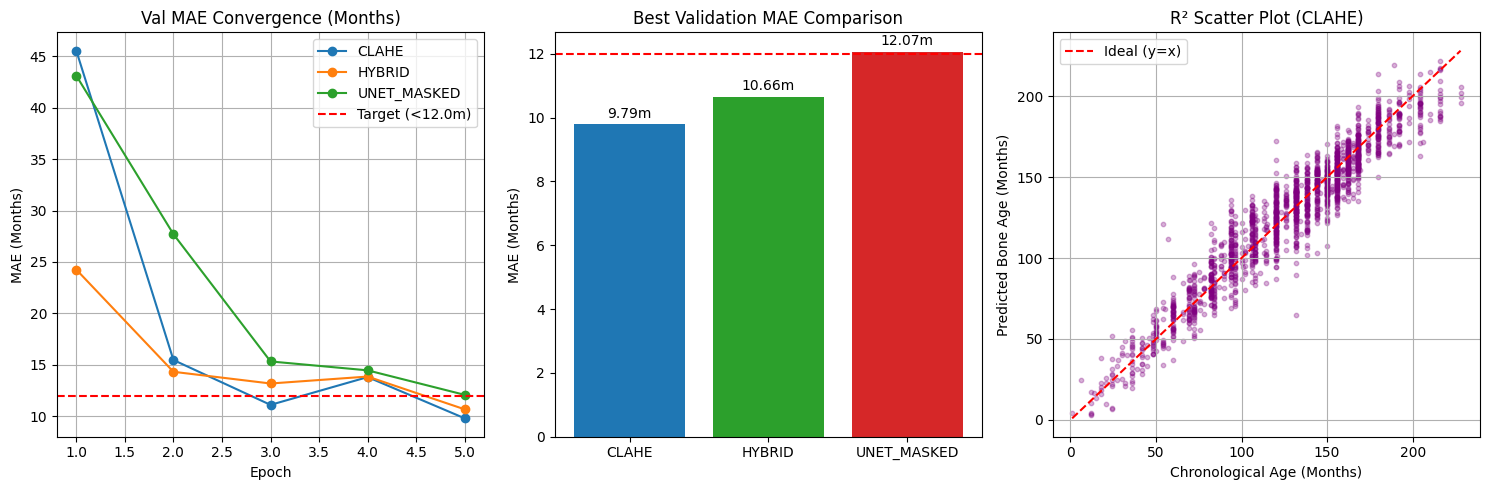

📊 Benchmarking visualizations saved to '/content/review3_multi_variant_evaluation_charts.png'.


In [9]:
# ==============================================================================
# Cell 5: Generate Comparative Charts, Convergence Curves, & R^2 Scatter Plots
# ==============================================================================
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 5))

# Plot 1: Validation MAE Convergence
plt.subplot(1, 3, 1)
for v in variants:
    with open(os.path.join(CHECKPOINT_DIR, f"history_{v}.json"), 'r') as f:
        data = json.load(f)
    plt.plot(range(1, len(data['val_mae']) + 1), data['val_mae'], label=v.upper(), marker='o')

plt.axhline(y=12.0, color='r', linestyle='--', label='Target (<12.0m)')
plt.title("Val MAE Convergence (Months)")
plt.xlabel("Epoch")
plt.ylabel("MAE (Months)")
plt.legend()
plt.grid(True)

# Plot 2: Final MAE & R^2 Performance Comparison
plt.subplot(1, 3, 2)
final_maes = []
labels = []
for v in variants:
    with open(os.path.join(CHECKPOINT_DIR, f"history_{v}.json"), 'r') as f:
        data = json.load(f)
    final_maes.append(min(data['val_mae']))
    labels.append(v.upper())

bars = plt.bar(labels, final_maes, color=['#1f77b4', '#2ca02c', '#d62728'])
plt.axhline(y=12.0, color='r', linestyle='--', label='Target')
plt.title("Best Validation MAE Comparison")
plt.ylabel("MAE (Months)")

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.1, f"{yval:.2f}m", ha='center', va='bottom')

# Plot 3: Best Variant R^2 Scatter Plot (Predicted vs Actual Age)
plt.subplot(1, 3, 3)
best_v = labels[np.argmin(final_maes)].lower()
pred_data = np.load(os.path.join(CHECKPOINT_DIR, f"predictions_{best_v}.npz"))
targets, preds = pred_data['targets'], pred_data['preds']

plt.scatter(targets, preds, alpha=0.3, color='purple', s=10)
plt.plot([min(targets), max(targets)], [min(targets), max(targets)], 'r--', label='Ideal (y=x)')
plt.title(f"R² Scatter Plot ({best_v.upper()})")
plt.xlabel("Chronological Age (Months)")
plt.ylabel("Predicted Bone Age (Months)")
plt.legend()
plt.grid(True)

plt.tight_layout()
chart_path = "/content/review3_multi_variant_evaluation_charts.png"
plt.savefig(chart_path, dpi=300)
plt.show()

print(f"📊 Benchmarking visualizations saved to '{chart_path}'.")

In [10]:
# ==============================================================================
# Cell 6: Sync All Models, JSON Logs & Plots to Google Drive
# ==============================================================================
DRIVE_BACKUP = "/content/drive/MyDrive/RSNA_Bone_Age/Review3_Artifacts"
os.makedirs(DRIVE_BACKUP, exist_ok=True)

!cp /content/checkpoints/* "{DRIVE_BACKUP}/" 2>/dev/null || true
!cp /content/review3_multi_variant_evaluation_charts.png "{DRIVE_BACKUP}/" 2>/dev/null || true

print(f"✅ Review 3 evaluation artifacts saved to Google Drive at '{DRIVE_BACKUP}'.")

✅ Review 3 evaluation artifacts saved to Google Drive at '/content/drive/MyDrive/RSNA_Bone_Age/Review3_Artifacts'.


In [11]:
# ==============================================================================
# Cell 7: Render Metric Table Image & Package Zip for Local Git Repository
# ==============================================================================
import os
import json
import zipfile
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

CHECKPOINT_DIR = "/content/checkpoints"
DOCS_DIR = "/content/docs"
os.makedirs(DOCS_DIR, exist_ok=True)

variants = ['clahe', 'hybrid', 'unet_masked']
table_data = []

# Compile metrics across all variants and epochs
for v in variants:
    json_path = os.path.join(CHECKPOINT_DIR, f"history_{v}.json")
    if os.path.exists(json_path):
        with open(json_path, 'r') as f:
            h = json.load(f)
        for ep in range(len(h['val_mae'])):
            table_data.append({
                "Variant": v.upper(),
                "Epoch": f"{ep+1:02d}",
                "Train Loss (MAE)": f"{h['train_loss'][ep]:.2f}m",
                "Val MAE": f"{h['val_mae'][ep]:.2f}m",
                "Val RMSE": f"{h['val_rmse'][ep]:.2f}m",
                "R² Score": f"{h['val_r2'][ep]:.4f}"
            })

df_metrics = pd.DataFrame(table_data)

# Render high-resolution PNG image of the results table
fig, ax = plt.subplots(figsize=(12, 6), dpi=300)
ax.axis('tight')
ax.axis('off')

tbl = ax.table(
    cellText=df_metrics.values,
    colLabels=df_metrics.columns,
    cellLoc='center',
    loc='center'
)

tbl.auto_set_font_size(False)
tbl.set_fontsize(10)
tbl.scale(1.2, 1.4)

# Apply header and alternating row styling
for (row, col), cell in tbl.get_celld().items():
    if row == 0:
        cell.set_facecolor('#2B4C7E')
        cell.set_text_props(color='white', weight='bold')
    else:
        variant_name = df_metrics.iloc[row-1]['Variant']
        if variant_name == 'CLAHE':
            cell.set_facecolor('#EBF3FA')
        elif variant_name == 'HYBRID':
            cell.set_facecolor('#EAF7ED')
        else:
            cell.set_facecolor('#FDF2F2')

table_img_path = os.path.join(DOCS_DIR, "review3_epoch_metrics_table.png")
plt.savefig(table_img_path, bbox_inches='tight', pad_inches=0.2)
plt.close()
print(f"✅ Metric table image generated: {table_img_path}")

# Copy comparative plots to docs directory
chart_source = "/content/review3_multi_variant_evaluation_charts.png"
chart_dest = os.path.join(DOCS_DIR, "review3_multi_variant_evaluation_charts.png")
if os.path.exists(chart_source):
    os.system(f"cp '{chart_source}' '{chart_dest}'")

# Create standalone Markdown report file for Git docs/
md_report_path = os.path.join(DOCS_DIR, "review3_benchmark_results.md")
with open(md_report_path, "w") as f:
    f.write("# Review 3 Preprocessing Variant Benchmarks\n\n")
    f.write("## Quantitative Metrics Across 15 Epochs\n\n")
    f.write(df_metrics.to_markdown(index=False))
    f.write("\n\n## Evaluation Figures\n\n")
    f.write("![Multi-Variant Evaluation Charts](review3_multi_variant_evaluation_charts.png)\n")
    f.write("![Epoch Metrics Table](review3_epoch_metrics_table.png)\n")

print(f"✅ Markdown report generated: {md_report_path}")

# Package all documentation artifacts into a ZIP file
zip_path = "/content/review3_docs_artifacts.zip"
with zipfile.ZipFile(zip_path, 'w') as zipf:
    for root, dirs, files_in_dir in os.walk(DOCS_DIR):
        for f in files_in_dir:
            full_p = os.path.join(root, f)
            arcname = os.path.relpath(full_p, DOCS_DIR)
            zipf.write(full_p, arcname)

print(f"📦 Archive created: {zip_path}")
files.download(zip_path)

✅ Metric table image generated: /content/docs/review3_epoch_metrics_table.png
✅ Markdown report generated: /content/docs/review3_benchmark_results.md
📦 Archive created: /content/review3_docs_artifacts.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

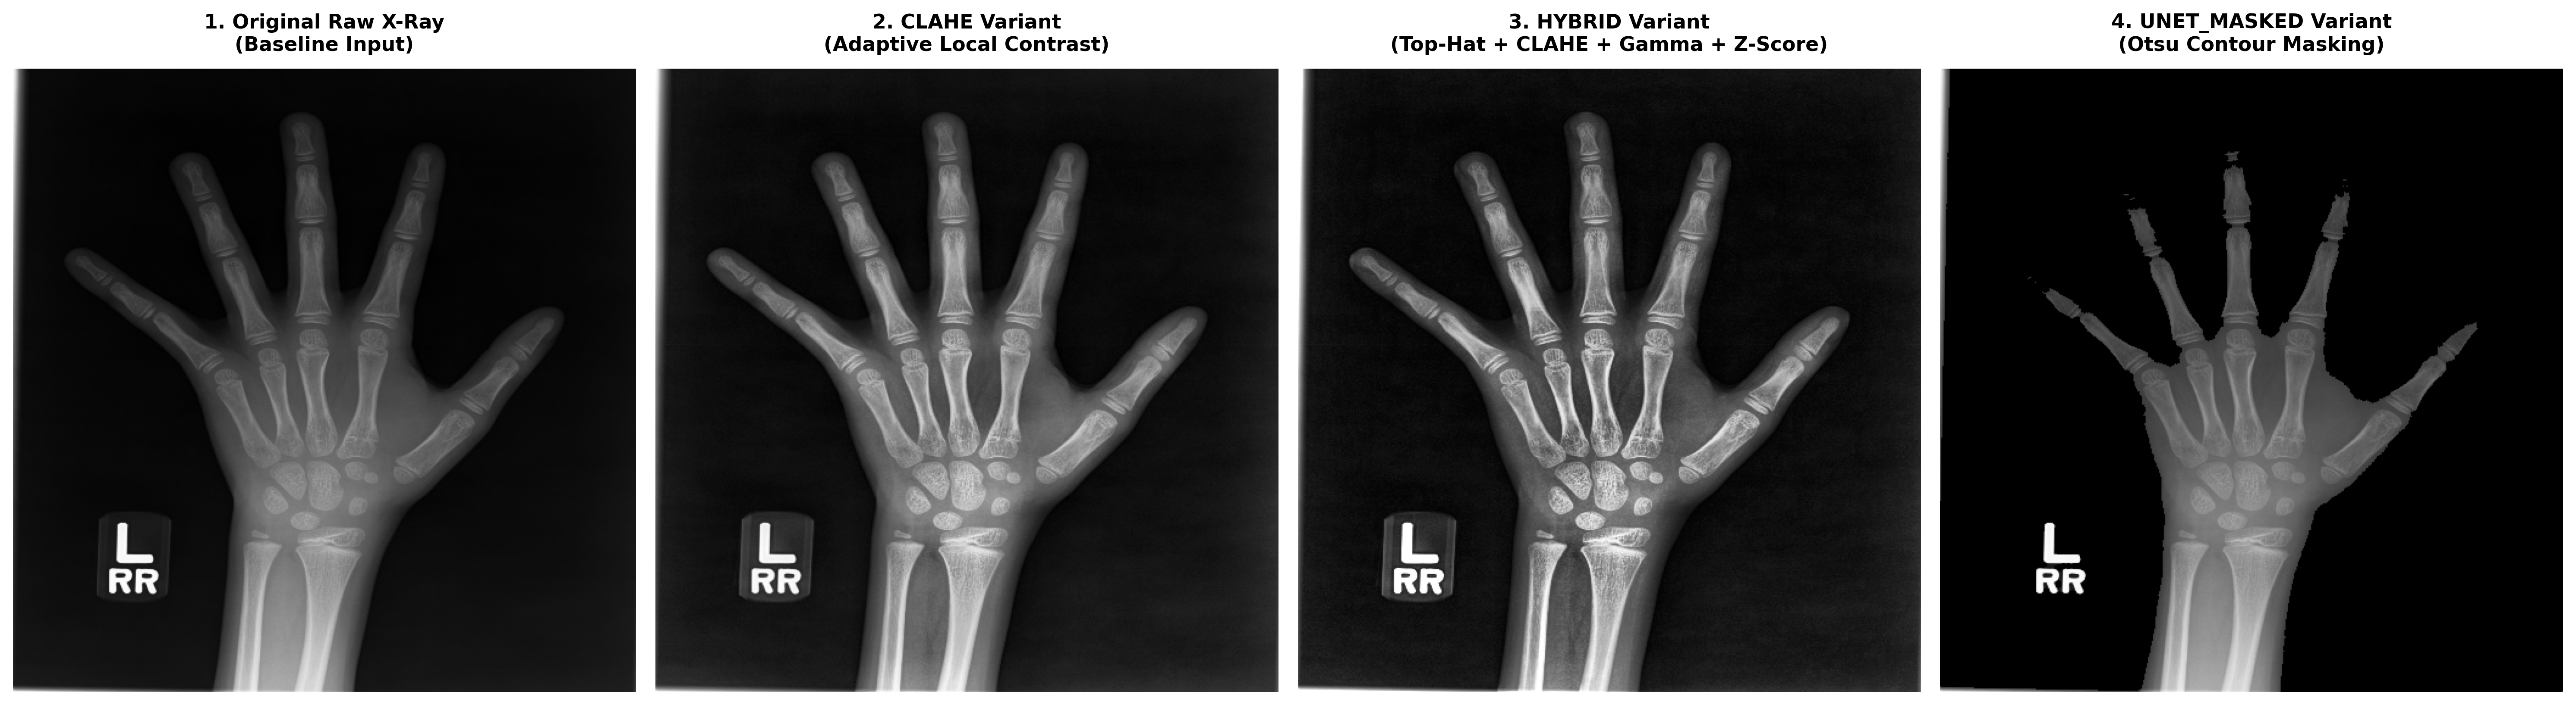

✅ Comparison grid saved to: /content/docs/review3_preprocessing_comparison.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [12]:
# ==============================================================================
# Cell 8: Generate Preprocessing Visual Samples (Raw vs CLAHE vs HYBRID vs UNET)
# ==============================================================================
import os
import cv2
import matplotlib.pyplot as plt
from google.colab import files

DOCS_DIR = "/content/docs"
os.makedirs(DOCS_DIR, exist_ok=True)

# Select a clean representative radiograph from the dataset
image_files = sorted([f for f in os.listdir(IMG_FOLDER) if f.endswith(('.png', '.jpg'))])
sample_fname = image_files[0]  # First dataset sample
src_path = os.path.join(IMG_FOLDER, sample_fname)

# Load and resize to standardized 512x512 resolution
img = cv2.imread(src_path, cv2.IMREAD_GRAYSCALE)
img_resized = cv2.resize(img, (512, 512))

# Generate preprocessed outputs
img_clahe = apply_clahe(img_resized)
img_hybrid = apply_hybrid(img_resized)
img_unet = apply_unet_masked(img_resized)

# Save individual PNG samples
cv2.imwrite(os.path.join(DOCS_DIR, "sample_raw.png"), img_resized)
cv2.imwrite(os.path.join(DOCS_DIR, "sample_clahe.png"), img_clahe)
cv2.imwrite(os.path.join(DOCS_DIR, "sample_hybrid.png"), img_hybrid)
cv2.imwrite(os.path.join(DOCS_DIR, "sample_unet_masked.png"), img_unet)

# Create 4-panel publication grid for panel slides
fig, axes = plt.subplots(1, 4, figsize=(20, 5.5), dpi=300)

axes[0].imshow(img_resized, cmap='gray')
axes[0].set_title("1. Original Raw X-Ray\n(Baseline Input)", fontsize=11, fontweight='bold', pad=10)
axes[0].axis('off')

axes[1].imshow(img_clahe, cmap='gray')
axes[1].set_title("2. CLAHE Variant\n(Adaptive Local Contrast)", fontsize=11, fontweight='bold', pad=10)
axes[1].axis('off')

axes[2].imshow(img_hybrid, cmap='gray')
axes[2].set_title("3. HYBRID Variant\n(Top-Hat + CLAHE + Gamma + Z-Score)", fontsize=11, fontweight='bold', pad=10)
axes[2].axis('off')

axes[3].imshow(img_unet, cmap='gray')
axes[3].set_title("4. UNET_MASKED Variant\n(Otsu Contour Masking)", fontsize=11, fontweight='bold', pad=10)
axes[3].axis('off')

plt.tight_layout()
comparison_path = os.path.join(DOCS_DIR, "review3_preprocessing_comparison.png")
plt.savefig(comparison_path, bbox_inches='tight', pad_inches=0.1)
plt.show()

print(f"✅ Comparison grid saved to: {comparison_path}")

# Download comparison PNG directly to local machine
files.download(comparison_path)